# PaisaPlan: LoRA fine-tuning of Llama 3.2 3B Instruct

Run the cells **top to bottom**. Runtime > Change runtime type > **T4 GPU** first.
Upload `train.jsonl` and `val.jsonl` in step 2.

## 1. Install

In [ ]:
%%capture
!pip install unsloth

## 2. Upload the data (choose train.jsonl AND val.jsonl)

In [ ]:
from google.colab import files
uploaded = files.upload()
print(list(uploaded))

Saving train.jsonl to train.jsonl
Saving val.jsonl to val.jsonl
['train.jsonl', 'val.jsonl']


## 3. Load the pre-trained model in 4-bit

In [ ]:
from unsloth import FastLanguageModel
import torch

max_seq_length = 2048
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name = "unsloth/Llama-3.2-3B-Instruct",
    max_seq_length = max_seq_length,
    dtype = None,
    load_in_4bit = True,
)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1115 12:35:52.855000 1294 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1115 12:35:52.893000 1294 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Unsloth: xformers is installed but cannot load with torch 2.14.1+cu130, so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.11.4: Fast Llama patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

Unsloth: Will load unsloth/Llama-3.2-3B-Instruct-unsloth-bnb-4bit as a legacy tokenizer.


## 4. Attach LoRA adapters (only these small weights get trained)

In [ ]:
model = FastLanguageModel.get_peft_model(
    model,
    r = 16,
    target_modules = ["q_proj","k_proj","v_proj","o_proj","gate_proj","up_proj","down_proj"],
    lora_alpha = 16,
    lora_dropout = 0,
    bias = "none",
    use_gradient_checkpointing = "unsloth",
    random_state = 3407,
)

Unsloth 2026.11.4 patched 28 layers with 28 QKV layers, 28 O layers and 28 MLP layers.


Unsloth: compiling each transformer block as one region (LlamaDecoderLayer).


## 5. Load and format the dataset

In [ ]:
from datasets import load_dataset
from unsloth.chat_templates import get_chat_template

tokenizer = get_chat_template(tokenizer, chat_template = "llama-3.1")
ds = load_dataset("json", data_files={"train": "train.jsonl", "validation": "val.jsonl"})

def fmt(batch):
    return {"text": [tokenizer.apply_chat_template(m, tokenize=False, add_generation_prompt=False) for m in batch["messages"]]}

ds = ds.map(fmt, batched=True)
print(ds)
print(ds["train"][0]["text"])

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Map:   0%|          | 0/612 [00:00<?, ? examples/s]

Map:   0%|          | 0/68 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['task', 'messages', 'text'],
        num_rows: 612
    })
    validation: Dataset({
        features: ['task', 'messages', 'text'],
        num_rows: 68
    })
})
<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 26 July 2024

You are the input parser for PaisaPlan, a budget planner. Convert the user's message into JSON with exactly these keys: income, fixed_costs, priorities, savings_goal, change_request. Output only the JSON. Use null (or an empty list) when something is not mentioned. Never invent numbers.<|eot_id|><|start_header_id|>user<|end_header_id|>

earning 26000, rent 8500, save twenty thousand in 5 months, savings and food are top priority<|eot_id|><|start_header_id|>assistant<|end_header_id|>

{"income": 26000, "fixed_costs": [{"name": "rent", "amount": 8500}], "priorities": ["savings", "food"], "savings_goal": {"amount": 20000, "months": 5}, "change_request":

## 6. Train (about 10-20 min on a T4). Watch that validation loss goes down.

In [ ]:
from trl import SFTTrainer, SFTConfig
from unsloth.chat_templates import train_on_responses_only

trainer = SFTTrainer(
    model = model,
    tokenizer = tokenizer,
    train_dataset = ds["train"],
    eval_dataset = ds["validation"],
    args = SFTConfig(
        dataset_text_field = "text",
        max_seq_length = max_seq_length,
        per_device_train_batch_size = 2,
        gradient_accumulation_steps = 4,
        num_train_epochs = 2,
        learning_rate = 2e-4,
        warmup_steps = 10,
        logging_steps = 5,
        eval_strategy = "steps",
        eval_steps = 20,
        optim = "adamw_8bit",
        weight_decay = 0.01,
        lr_scheduler_type = "linear",
        seed = 3407,
        output_dir = "outputs",
        report_to = "none",
    ),
)
# train only on the assistant's answer, not on the prompt
trainer = train_on_responses_only(
    trainer,
    instruction_part = "<|start_header_id|>user<|end_header_id|>\n\n",
    response_part = "<|start_header_id|>assistant<|end_header_id|>\n\n",
)
trainer.train()

Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/612 [00:00<?, ? examples/s]

Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/68 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


Map:   0%|          | 0/612 [00:00<?, ? examples/s]

... (3 outputs left out)

Step,Training Loss,Validation Loss
20,0.267472,0.115407
40,0.025010,0.021470
60,0.019045,0.022697
80,0.012188,0.013399
100,0.011041,0.011172
120,0.007670,0.008117
140,0.007380,0.007896
154,0.004897,0.007835


Filter:   0%|          | 0/68 [00:00<?, ? examples/s]

Unsloth: Not an error, but `num_items_in_batch` could not be counted for LlamaForCausalLM's labels, so each micro-batch loss is a mean.
Using gradient accumulation will be very slightly less accurate.
Read more on gradient accumulation issues here: https://unsloth.ai/blog/gradient
Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-154/tokenizer_config.json.


TrainOutput(global_step=154, training_loss=0.0904393612419243, metrics={'train_runtime': 488.8788, 'train_samples_per_second': 2.504, 'train_steps_per_second': 0.315, 'total_flos': 4239379604852736.0, 'train_loss': 0.0904393612419243, 'epoch': 2.0})

## 7. Loss curve (save this for the report)

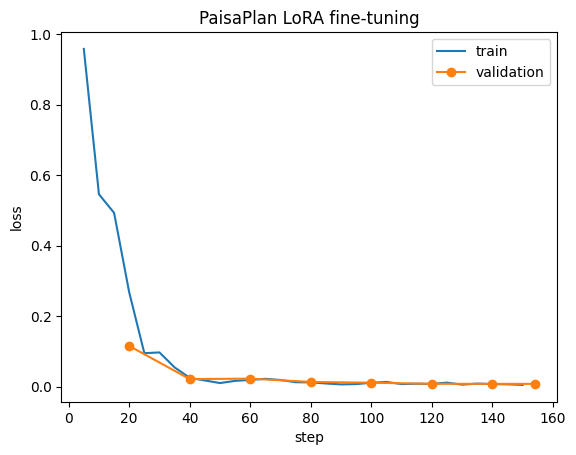

In [ ]:
import matplotlib.pyplot as plt
logs = trainer.state.log_history
tr = [(l["step"], l["loss"]) for l in logs if "loss" in l]
ev = [(l["step"], l["eval_loss"]) for l in logs if "eval_loss" in l]
plt.plot(*zip(*tr), label="train")
plt.plot(*zip(*ev), label="validation", marker="o")
plt.xlabel("step"); plt.ylabel("loss"); plt.legend(); plt.title("PaisaPlan LoRA fine-tuning")
plt.savefig("loss_curve.png", dpi=150)
plt.show()

## 8. Quick test on new messages

In [ ]:
EXTRACT_SYS = "You are the input parser for PaisaPlan, a budget planner. Convert the user's message into JSON with exactly these keys: income, fixed_costs, priorities, savings_goal, change_request. Output only the JSON. Use null (or an empty list) when something is not mentioned. Never invent numbers."
EXPLAIN_SYS = "You are the explainer for PaisaPlan, a budget planner. You receive solver results as JSON. Explain them in plain, friendly language. Use only numbers that appear in the JSON and never calculate new ones. Mark facts as [CERTAIN] and projections as [ESTIMATE: reason]."

FastLanguageModel.for_inference(model)

def ask(system, user):
    msgs = [{"role":"system","content":system},{"role":"user","content":user}]
    ids = tokenizer.apply_chat_template(msgs, tokenize=True, add_generation_prompt=True, return_tensors="pt").to("cuda")
    out = model.generate(input_ids=ids, max_new_tokens=300, do_sample=False)
    return tokenizer.decode(out[0][ids.shape[1]:], skip_special_tokens=True)

for m in ["my stipend is 22k, hostel 7000, wanna save 6000 in 3 months",
          "what if I spend 1500 less on travel",
          "salary thirty five thousand, fees 4k, food first then savings"]:
    print(m, "->", ask(EXTRACT_SYS, m), "\n")

Both `max_new_tokens` (=300) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
Both `max_new_tokens` (=300) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


my stipend is 22k, hostel 7000, wanna save 6000 in 3 months -> {"income": 22000, "fixed_costs": [{"name": "rent", "amount": 7000}], "priorities": [], "savings_goal": {"amount": 6000, "months": 3}, "change_request": null} 



Both `max_new_tokens` (=300) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


what if I spend 1500 less on travel -> {"income": null, "fixed_costs": [], "priorities": [], "savings_goal": null, "change_request": {"category": "transport", "action": "decrease", "amount": 1500}} 

salary thirty five thousand, fees 4k, food first then savings -> {"income": 35000, "fixed_costs": [{"name": "education", "amount": 4000}], "priorities": ["food", "savings"], "savings_goal": null, "change_request": null} 



## 9. Save adapter and export GGUF for Ollama

In [ ]:
model.save_pretrained("lora_adapter")
tokenizer.save_pretrained("lora_adapter")
model.save_pretrained_gguf("paisaplan_gguf", tokenizer, quantization_method = "q4_k_m")

Unsloth: Restored added_tokens_decoder metadata in lora_adapter/tokenizer_config.json.
Unsloth: ##### The current model auto adds a BOS token.
Unsloth: ##### Your chat template has a BOS token. We shall remove it temporarily.


Unsloth: Merging model weights to 16-bit format...


config.json:   0%|          | 0.00/890 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/20.9k [00:00<?, ?B/s]

Unsloth: Restored added_tokens_decoder metadata in paisaplan_gguf/tokenizer_config.json.


Found HuggingFace hub cache directory: /root/.cache/huggingface/hub


... (12 outputs left out)

Unsloth: Merge process complete. Saved to `/content/paisaplan_gguf`
Unsloth: Converting to GGUF format...
==((====))==  Unsloth: Conversion from HF to GGUF information
   \\   /|    [0] Installing llama.cpp might take 3 minutes.
O^O/ \_/ \    [1] Converting HF to GGUF f16 might take 3 minutes.
\        /    [2] Converting GGUF f16 to ['q4_k_m'] might take 10 minutes each.
 "-____-"     In total, you will have to wait at least 16 minutes.

Unsloth: Installing llama.cpp. This might take 3 minutes...
Unsloth: Installing prebuilt llama.cpp b12347-mix-241a0f3 (app-b12347-mix-241a0f3-linux-x64-cpu.tar.gz) - skipping compilation.
Unsloth: Preparing converter script...
Unsloth: [1] Converting model into f16 GGUF format.
This might take 3 minutes...
Unsloth: Initial conversion completed! Files: ['paisaplan_gguf_gguf/Llama-3.2-3B-Instruct.F16.gguf']
Unsloth: [2] Converting GGUF f16 into q4_k_m. This might take 10 minutes...


Unsloth: ##### The current model auto adds a BOS token.
Unsloth: ##### We removed it in GGUF's chat template for you.


Unsloth: Model files cleanup...
Unsloth: All GGUF conversions completed successfully!
Generated files: ['paisaplan_gguf_gguf/Llama-3.2-3B-Instruct.Q4_K_M.gguf']
Unsloth: example usage for text only LLMs: /root/.unsloth/llama.cpp/llama-cli --model paisaplan_gguf_gguf/Llama-3.2-3B-Instruct.Q4_K_M.gguf -p "why is the sky blue?"
Unsloth: Saved Ollama Modelfile to paisaplan_gguf_gguf/Modelfile
Unsloth: convert model to ollama format by running - ollama create model_name -f paisaplan_gguf_gguf/Modelfile


{'save_directory': 'paisaplan_gguf',
 'gguf_directory': 'paisaplan_gguf_gguf',
 'gguf_files': ['paisaplan_gguf_gguf/Llama-3.2-3B-Instruct.Q4_K_M.gguf'],
 'modelfile_location': 'paisaplan_gguf_gguf/Modelfile',
 'want_full_precision': False,
 'is_vlm': False,
 'fix_bos_token': True}

## 10. Copy everything to Google Drive (the GGUF is ~2 GB, so Drive is easier than a browser download)

In [ ]:
from google.colab import drive, files
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/paisaplan
!cp -r paisaplan_gguf lora_adapter loss_curve.png /content/drive/MyDrive/paisaplan/
files.download('loss_curve.png')

Mounted at /content/drive


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
from google.colab import files
!zip -r lora_adapter.zip lora_adapter
files.download('loss_curve.png')
files.download('lora_adapter.zip')

  adding: lora_adapter/ (stored 0%)
  adding: lora_adapter/adapter_config.json (deflated 60%)
  adding: lora_adapter/chat_template.jinja (deflated 72%)
  adding: lora_adapter/adapter_model.safetensors (deflated 7%)
  adding: lora_adapter/tokenizer.json (deflated 85%)
  adding: lora_adapter/tokenizer_config.json (deflated 96%)
  adding: lora_adapter/README.md (deflated 65%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
!mkdir -p /content/drive/MyDrive/paisaplan
!cp -r paisaplan_gguf_gguf /content/drive/MyDrive/paisaplan/
!ls -la /content/drive/MyDrive/paisaplan/paisaplan_gguf_gguf

total 1972060
drwx------ 2 root root       4096 Nov 15 13:28 .
drwx------ 5 root root       4096 Nov 15 13:28 ..
-rw------- 1 root root 2019378240 Nov 15 13:28 Llama-3.2-3B-Instruct.Q4_K_M.gguf
-rw------- 1 root root       1922 Nov 15 13:28 Modelfile
